In [1]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd



Loaded: thinfilm_closure_data_Re120_Ca0_010_theta45.h5
Grid: nx=16384, paired snapshots=200
Re=120, Fr2=28.2843, We=1.2, Lambda=3
Angle: 45 degrees
Paired dt range: [0.00300227, 0.00471787]
Statistics region: x in [40.0635, 759.937]
Selected midpoint: 1800 (tm=1800, t=1800)
mass                  : median spatial RMS=5.448541e-03, maximum spatial RMS=1.441931e-02
momentum_lavalle      : median spatial RMS=1.490096e-01, maximum spatial RMS=3.309360e-01
momentum_corrected    : median spatial RMS=3.367796e-02, maximum spatial RMS=4.531189e-02


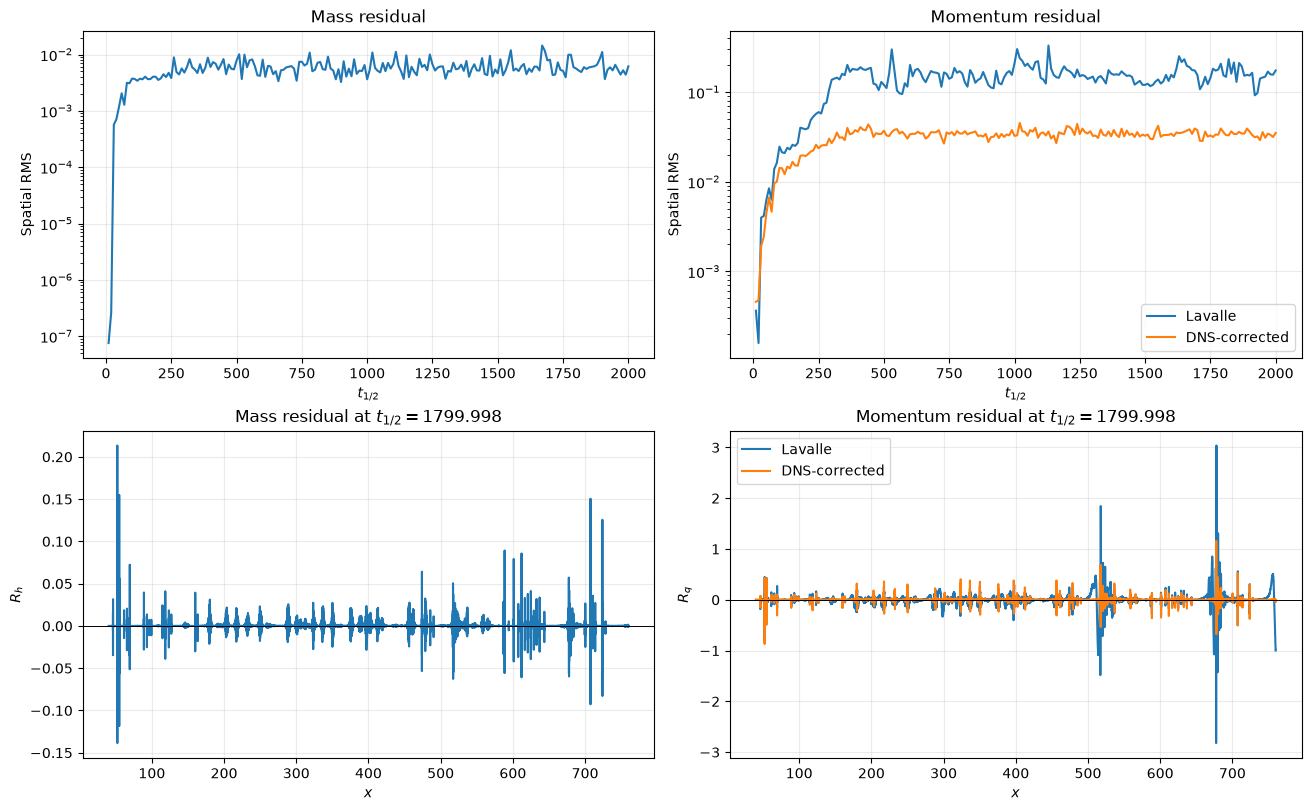

In [6]:
# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------
RE = 120
CA = 0.01
BETA = 45
TIME_TARGET = 1800.0

# Fraction of physical domain length excluded at EACH boundary
# when calculating statistics. Full residual fields are retained.
EDGE_FRACTION = 0.05

DATA_DIR = Path(
    "/blue/bala1s/krishnap.kalivel/"
    "TLFHydrodynamics/thinfilm-closure-ml/"
    "datasets/BasC/param_space/ClosureData"
)

filepath = DATA_DIR / (
    f"thinfilm_closure_data_Re{RE:03d}_"
    f"Ca{CA:.3f}".replace(".", "_")
    + f"_theta{BETA:g}".replace(".", "_")
    + ".h5"
)

# Fields needed at BOTH endpoints of each time pair.
FIELD_NAMES = [
    "h",
    "q",
    "q_x",
    "q_xx",
    "h_xxx",
    "delta_M_ML",
    "delta_Tw_ML",
    "delta_Px_ML",
    "delta_Dx_ML",
]

# ---------------------------------------------------------
# Load all required spatial profiles at all stored times
# ---------------------------------------------------------
with h5py.File(filepath, "r") as f:
    x = np.asarray(f["x"][:], dtype=float).reshape(-1)
    t = np.asarray(f["t"][:], dtype=float).reshape(-1)
    tm = np.asarray(f["tm"][:], dtype=float).reshape(-1)

    nx, nt = x.size, t.size

    def read_field(name):
        dataset = f[name]

        if dataset.shape == (nx, nt):
            values = np.asarray(dataset[:], dtype=float)
        elif dataset.shape == (nt, nx):
            values = np.asarray(dataset[:], dtype=float).T
        else:
            raise ValueError(
                f"{name}: unexpected shape {dataset.shape}; "
                f"expected {(nx, nt)} or {(nt, nx)}."
            )

        if not np.all(np.isfinite(values)):
            raise ValueError(f"{name} contains NaN or Inf.")

        return values

    current = {name: read_field(name) for name in FIELD_NAMES}
    previous = {
        name: read_field(name + "_m") for name in FIELD_NAMES
    }

    def read_parameter(name):
        value = np.asarray(f["parameters"][name][()])
        if value.size != 1:
            raise ValueError(f"Parameter {name} is not scalar.")
        return float(value.reshape(-1)[0])

    Re = read_parameter("Re")
    Fr2 = read_parameter("Fr2")
    We = read_parameter("We")
    Lambda = read_parameter("Lambda")
    angle = read_parameter("angle")
    Ca = read_parameter("Ca")

# ---------------------------------------------------------
# Validate coordinates and paired times
# ---------------------------------------------------------
if nx < 3 or not np.all(np.isfinite(x)) or np.any(np.diff(x) <= 0):
    raise ValueError("x must contain at least 3 finite, increasing points.")

if tm.shape != t.shape:
    raise ValueError("t and tm must have the same shape.")

if not np.all(np.isfinite(t)) or not np.all(np.isfinite(tm)):
    raise ValueError("t and tm must be finite.")

if np.any(np.diff(t) <= 0):
    raise ValueError("Stored times t must be strictly increasing.")

# Use the actual time separation of each paired snapshot.
dt_pair = t - tm

if np.any(dt_pair <= 0):
    raise ValueError("Every paired snapshot must satisfy t > tm.")

if Re <= 0 or Fr2 <= 0 or We <= 0:
    raise ValueError("Re, Fr2, and We must be positive.")

if np.any(current["h"] <= 0) or np.any(previous["h"] <= 0):
    raise ValueError("Non-positive film thickness encountered.")

if not 0 <= EDGE_FRACTION < 0.5:
    raise ValueError("EDGE_FRACTION must lie in [0, 0.5).")

t_mid = 0.5 * (t + tm)

def dx(values):
    """Spatial derivative; arrays have shape (nx, nt)."""
    return np.gradient(values, x, axis=0, edge_order=2)

def midpoint_term(function):
    """Evaluate a term at each endpoint, then average."""
    return 0.5 * (function(current) + function(previous))

# ---------------------------------------------------------
# Time derivatives centered at the paired-time midpoints
# ---------------------------------------------------------
h_t = (current["h"] - previous["h"]) / dt_pair[None, :]
q_t = (current["q"] - previous["q"]) / dt_pair[None, :]

# ---------------------------------------------------------
# Baseline Lavalle terms
# ---------------------------------------------------------
def lavalle_flux(state):
    h, q = state["h"], state["q"]

    return (
        q**2 / h
        + (2.0 * Lambda**2 / 225.0) * h**5
        + (np.cos(angle) / (2.0 * Fr2)) * h**2
    )

def gravity_minus_wall(state):
    h, q = state["h"], state["q"]
    return (Lambda * h - 3.0 * q / h**2) / Re

q_x_mid = midpoint_term(lambda s: s["q_x"])

# The derivative operator is linear, so differentiating the
# averaged flux equals averaging its endpoint derivatives.
flux_x_mid = dx(midpoint_term(lavalle_flux))

source_mid = midpoint_term(gravity_minus_wall)
source_mid += midpoint_term(lambda s: s["h"] * s["h_xxx"] / We)
source_mid += midpoint_term(lambda s: (2.0 / Re) * s["q_xx"])

# ---------------------------------------------------------
# DNS corrections, with signs appropriate to the RHS
# ---------------------------------------------------------
correction_rhs = -dx(midpoint_term(lambda s: s["delta_M_ML"]))
correction_rhs -= midpoint_term(lambda s: s["delta_Tw_ML"])
correction_rhs += midpoint_term(lambda s: s["delta_Px_ML"])
correction_rhs += midpoint_term(lambda s: s["delta_Dx_ML"])

# ---------------------------------------------------------
# Residual fields: shape (nx, nt)
# ---------------------------------------------------------
residuals = {
    "mass": h_t + q_x_mid,
    "momentum_lavalle": q_t + flux_x_mid - source_mid,
}

residuals["momentum_corrected"] = (
    residuals["momentum_lavalle"] - correction_rhs
)

# ---------------------------------------------------------
# Spatial statistics at EVERY paired-time midpoint
# ---------------------------------------------------------
domain_length = x[-1] - x[0]

interior = (
    (x >= x[0] + EDGE_FRACTION * domain_length)
    & (x <= x[-1] - EDGE_FRACTION * domain_length)
)

if np.count_nonzero(interior) < 3:
    raise ValueError("Too few spatial points in the statistics region.")

x_eval = x[interior]
eval_length = x_eval[-1] - x_eval[0]

# Compatible with NumPy versions before and after 2.0.
integrate = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

def spatial_rms(field):
    values = field[interior, :]
    return np.sqrt(
        integrate(values**2, x=x_eval, axis=0) / eval_length
    )

stats = {}

for name, field in residuals.items():
    stats[name] = {
        "rms": spatial_rms(field),
        "linf": np.max(np.abs(field[interior, :]), axis=0),
    }

# Reference scales use individual balance terms.
# These help distinguish small absolute residuals from small
# residuals relative to the quantities being balanced.
mass_scale = spatial_rms(h_t) + spatial_rms(q_x_mid)

momentum_scale = (
    spatial_rms(q_t)
    + spatial_rms(flux_x_mid)
    + spatial_rms(source_mid)
    + spatial_rms(correction_rhs)
)

def safe_ratio(numerator, denominator):
    result = np.full_like(numerator, np.nan, dtype=float)
    np.divide(
        numerator, denominator,
        out=result, where=denominator > 0
    )
    return result

stats["mass"]["relative_rms"] = safe_ratio(
    stats["mass"]["rms"], mass_scale
)

# Use the SAME scale for the two momentum residuals.
for name in ["momentum_lavalle", "momentum_corrected"]:
    stats[name]["relative_rms"] = safe_ratio(
        stats[name]["rms"], momentum_scale
    )

# ---------------------------------------------------------
# Summary and selected profile
# ---------------------------------------------------------
it = int(np.argmin(np.abs(t_mid - TIME_TARGET)))

print(f"Loaded: {filepath.name}")
print(f"Grid: nx={nx}, paired snapshots={nt}")
print(f"Re={Re:g}, Fr2={Fr2:g}, We={We:g}, Lambda={Lambda:g}")
print(f"Angle: {np.rad2deg(angle):g} degrees")
print(f"Paired dt range: [{dt_pair.min():.6g}, {dt_pair.max():.6g}]")
print(f"Statistics region: x in [{x_eval[0]:g}, {x_eval[-1]:g}]")
print(
    f"Selected midpoint: {t_mid[it]:.6g} "
    f"(tm={tm[it]:.6g}, t={t[it]:.6g})"
)

for name in residuals:
    rms = stats[name]["rms"]
    print(
        f"{name:22s}: "
        f"median spatial RMS={np.median(rms):.6e}, "
        f"maximum spatial RMS={np.max(rms):.6e}"
    )

# ---------------------------------------------------------
# Plots
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

# Avoid log(0) in plots without modifying the stored statistics.
plot_floor = np.finfo(float).tiny

axes[0, 0].semilogy(
    t_mid,
    np.maximum(stats["mass"]["rms"], plot_floor),
)
axes[0, 0].set(
    xlabel=r"$t_{1/2}$",
    ylabel="Spatial RMS",
    title="Mass residual",
)

for name, label in [
    ("momentum_lavalle", "Lavalle"),
    ("momentum_corrected", "DNS-corrected"),
]:
    axes[0, 1].semilogy(
        t_mid,
        np.maximum(stats[name]["rms"], plot_floor),
        label=label,
    )

axes[0, 1].set(
    xlabel=r"$t_{1/2}$",
    ylabel="Spatial RMS",
    title="Momentum residual",
)
axes[0, 1].legend()

axes[1, 0].plot(
    x_eval, residuals["mass"][interior, it]
)
axes[1, 0].axhline(0, color="k", linewidth=0.7)
axes[1, 0].set(
    xlabel=r"$x$",
    ylabel=r"$R_h$",
    title=fr"Mass residual at $t_{{1/2}}={t_mid[it]:.3f}$",
)

for name, label in [
    ("momentum_lavalle", "Lavalle"),
    ("momentum_corrected", "DNS-corrected"),
]:
    axes[1, 1].plot(
        x_eval, residuals[name][interior, it], label=label
    )

axes[1, 1].axhline(0, color="k", linewidth=0.7)
axes[1, 1].set(
    xlabel=r"$x$",
    ylabel=r"$R_q$",
    title=fr"Momentum residual at $t_{{1/2}}={t_mid[it]:.3f}$",
)
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.show()

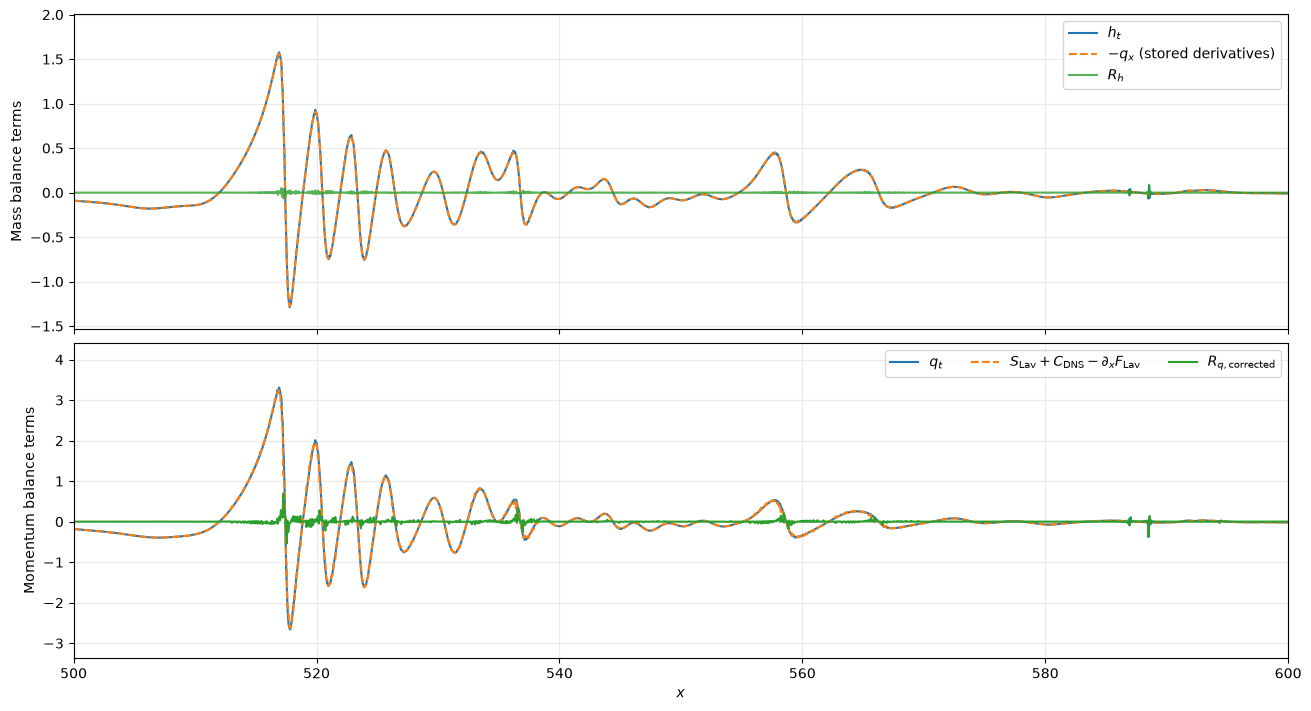

In [3]:
it = int(np.argmin(np.abs(t_mid - TIME_TARGET)))
xs = x[interior]

fig, axes = plt.subplots(
    2, 1, figsize=(13, 7), sharex=True, constrained_layout=True
)

axes[0].plot(xs, h_t[interior, it], label=r"$h_t$")
axes[0].plot(
    xs, -q_x_mid[interior, it], "--",
    label=r"$-q_x$ (stored derivatives)"
)
axes[0].plot(
    xs, residuals["mass"][interior, it],
    label=r"$R_h$", alpha=0.8
)
axes[0].set_ylabel("Mass balance terms")
axes[0].legend()

# Compare each signed contribution to the momentum residual.
# Compare q_t with the combined remaining terms,
# while retaining the individual contributions.
for field, label in [
    (q_t, r"$q_t$"),

    (
        source_mid + correction_rhs - flux_x_mid,
        r"$S_{\mathrm{Lav}}+C_{\mathrm{DNS}}-\partial_x F_{\mathrm{Lav}}$",
    ),

    # (flux_x_mid, r"$\partial_x F_{\mathrm{Lav}}$"),
    # (-source_mid, r"$-S_{\mathrm{Lav}}$"),
    # (-correction_rhs, r"$-C_{\mathrm{DNS}}$"),
    (residuals["momentum_corrected"], r"$R_{q,\mathrm{corrected}}$"),
]:
    # Dashed line for the combined balance to reveal overlap.
    linestyle = "--" if label.startswith(r"$S_{\mathrm{Lav}}") else "-"
    axes[1].plot(
        xs, field[interior, it],
        linestyle=linestyle, label=label,
    )

axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel("Momentum balance terms")
axes[1].legend(ncol=3)
axes[1].set_xlim(500,600)
# axes[1].set_ylim(-0.5, 0.5)

for ax in axes:
    ax.grid(alpha=0.25)

plt.show()

# print(f"Paired time separation: {dt_pair[it]:.8g}")
# print(
#     "Mass relative RMS:",
#     stats["mass"]["relative_rms"][it]
# )
# print(
#     "Corrected momentum relative RMS:",
#     stats["momentum_corrected"]["relative_rms"][it]
# )



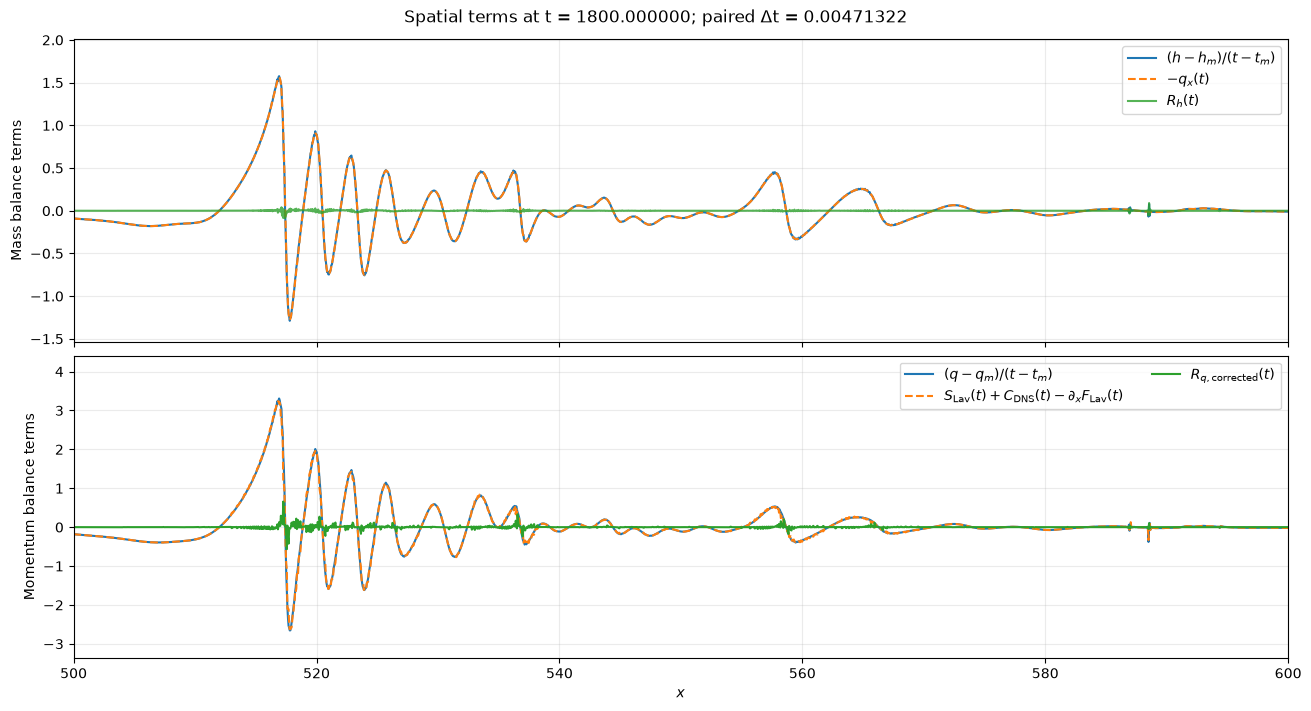

In [4]:
# ---------------------------------------------------------
# Spatial terms evaluated at the CURRENT time t
# ---------------------------------------------------------
q_x_at_t = current["q_x"]

flux_x_at_t = dx(lavalle_flux(current))

source_at_t = (
    gravity_minus_wall(current)
    + current["h"] * current["h_xxx"] / We
    + (2.0 / Re) * current["q_xx"]
)

correction_rhs_at_t = (
    -dx(current["delta_M_ML"])
    - current["delta_Tw_ML"]
    + current["delta_Px_ML"]
    + current["delta_Dx_ML"]
)

# Same paired differences as before, now interpreted as
# backward approximations to the derivatives at t.
h_t_backward = h_t
q_t_backward = q_t

momentum_rhs_at_t = (
    source_at_t + correction_rhs_at_t - flux_x_at_t
)

residuals_at_t = {
    "mass": h_t_backward + q_x_at_t,
    "momentum_lavalle": (
        q_t_backward + flux_x_at_t - source_at_t
    ),
    "momentum_corrected": q_t_backward - momentum_rhs_at_t,
}

# Select using t, rather than t_mid.
it = int(np.argmin(np.abs(t - TIME_TARGET)))
xs = x[interior]

fig, axes = plt.subplots(
    2, 1, figsize=(13, 7), sharex=True, constrained_layout=True
)

axes[0].plot(
    xs, h_t_backward[interior, it],
    label=r"$(h-h_m)/(t-t_m)$",
)
axes[0].plot(
    xs, -q_x_at_t[interior, it], "--",
    label=r"$-q_x(t)$",
)
axes[0].plot(
    xs, residuals_at_t["mass"][interior, it],
    label=r"$R_h(t)$", alpha=0.8,
)
axes[0].set_ylabel("Mass balance terms")
axes[0].legend()

# Comment out individual entries as desired.
for field, label, linestyle in [
    (
        q_t_backward,
        r"$(q-q_m)/(t-t_m)$",
        "-",
    ),
    (
        momentum_rhs_at_t,
        r"$S_{\mathrm{Lav}}(t)+C_{\mathrm{DNS}}(t)"
        r"-\partial_x F_{\mathrm{Lav}}(t)$",
        "--",
    ),
    # (flux_x_at_t, r"$\partial_x F_{\mathrm{Lav}}(t)$", "-"),
    # (-source_at_t, r"$-S_{\mathrm{Lav}}(t)$", "-"),
    # (-correction_rhs_at_t, r"$-C_{\mathrm{DNS}}(t)$", "-"),
    (
        residuals_at_t["momentum_corrected"],
        r"$R_{q,\mathrm{corrected}}(t)$",
        "-",
    ),
]:
    axes[1].plot(
        xs, field[interior, it],
        linestyle=linestyle, label=label,
    )

axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel("Momentum balance terms")
axes[1].legend(ncol=2)
axes[1].set_xlim(500, 600)
fig.suptitle(
    f"Spatial terms at t = {t[it]:.6f}; "
    f"paired Δt = {dt_pair[it]:.6g}"
)

for ax in axes:
    ax.grid(alpha=0.25)

plt.show()

In [7]:
Ca

0.01

In [8]:
x[1]-x[0]

np.float64(0.048828125)